# Inference demo: detector on 5 freshly generated spectrograms

Loads `runs/detector_1cls_yolo26s_1/best.pt` (single-class YOLO26s signal detector) and runs it on **5 random synthetic scenes**.
Each scene holds **1 to 5 signals** with a random modulation and a random SNR (5 to 10 dB, set by `SNR_RANGE`). The signals are made with the *same generator* as `01_create_dataset.ipynb` (its code cells are executed here, so nothing is duplicated).

On every plot: solid boxes = ground truth with **modulation + SNR** label, dashed red boxes = detector output with confidence.

numpy 2.5.4 | scipy 1.18.1 | pandas 3.1.0 | python 3.12.11
profile=pilot  scenes=15,000  workers=14  store_iq=True
samples/scene=33536  duration=131.0 ms  bin width=250 Hz  window=4.0 ms  out=dataset/spectrum_rf_v0.2.0_pilot


/Users/tohid/Desktop/RF-Signal-Detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


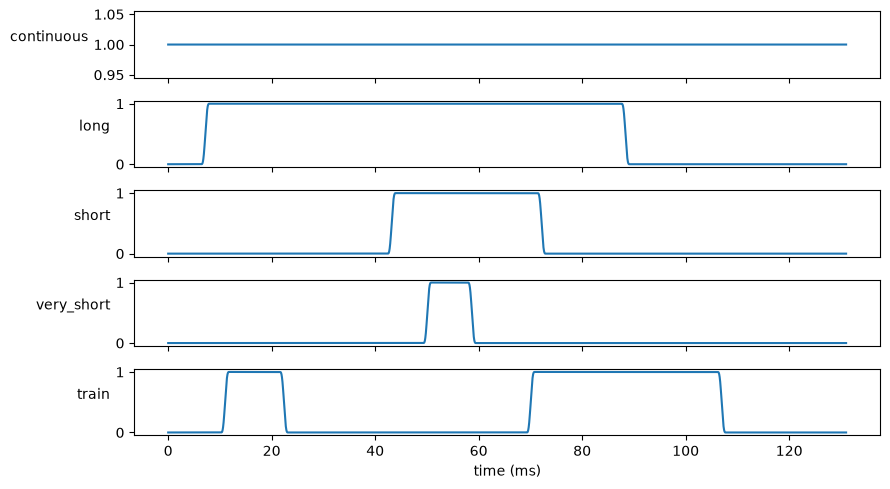

generator ready: ['CW', 'AM', 'NBFM', 'BPSK', 'QPSK', '8PSK', '16QAM', '64QAM', '2-FSK', '4-FSK', 'GMSK']


In [1]:
import json, sys
from pathlib import Path
import numpy as np

ROOT = Path.cwd()
nb_src = json.loads((ROOT / "01_create_dataset.ipynb").read_text())
# generator cells: imports, config, classes, signals, bursts, receiver, scene composer, sessions (stop before the demo at the end of the last one)
for idx in (1, 3, 5, 7, 9, 11, 13, 15):
    src = "".join(nb_src["cells"][idx]["source"])
    src = src.split("_demo = make_specs")[0]
    exec(compile(src, f"01_create_dataset.ipynb[cell {idx}]", "exec"), globals())
print("generator ready:", [c[1] for c in CLASS_TABLE])

In [2]:
sys.path.insert(0, str(ROOT))
from train_detector import Detector
from spectrum_common import box_iou_matrix

WEIGHTS = ROOT / "runs/detector_1cls_yolo26s_6/best.pt"
det = Detector(WEIGHTS, conf=0.25)
print("imgsz", det.imgsz, "| device", det.device, "| single class", det.single_class)

imgsz 1536 | device mps | single class True


## 1. Generate 5 random scenes (1 to 5 signals each)

In [3]:
SEED = None          # set an int for reproducible scenes
rng = np.random.default_rng(SEED)
CLASSES = [c[1] for c in CLASS_TABLE]
SNR_RANGE = (5.0, 10.0)                       # dB, every signal gets an SNR in this range
N_SCENES = 5
n_sigs = [1, 2, 3, 4, 5]                       # one scene per signal count ...
n_sigs = list(rng.permutation(n_sigs))         # ... in random order (use rng.integers(1, 6, N_SCENES) for fully random counts)

scenes = []
for k, n in enumerate(n_sigs):
    spec = make_specs("val", 0, 1)[0]
    spec["seed"] = int(rng.integers(0, 2**63 - 1))
    spec["scene_id"] = f"demo_{k}"
    spec["session"] = session_for_group(SET_IDS["val"], int(rng.integers(0, 30)), "train")
    spec["force"] = [dict(cls=str(rng.choice(CLASSES)), snr_db=float(rng.uniform(*SNR_RANGE)),
                          btype=str(rng.choice(CFG.burst_types, p=CFG.burst_probs))) for _ in range(int(n))]
    sc = make_scene(spec)
    sc["db"] = dequantize_db(sc["spec"])
    scenes.append(sc)
    print(f"scene {k}: {n} signals ->", [f'{r["class_name"]} @ {r["snr_db"]:.1f} dB' for r in sc["signals"]])

scene 0: 1 signals -> ['64QAM @ 5.9 dB']
scene 1: 4 signals -> ['NBFM @ 6.3 dB', 'CW @ 5.9 dB', 'GMSK @ 8.8 dB', '64QAM @ 10.0 dB']
scene 2: 2 signals -> ['64QAM @ 5.9 dB', '2-FSK @ 5.6 dB', '2-FSK @ 5.6 dB']
scene 3: 3 signals -> ['8PSK @ 9.6 dB', '4-FSK @ 6.9 dB', 'GMSK @ 6.6 dB']
scene 4: 5 signals -> ['CW @ 7.2 dB', 'NBFM @ 5.2 dB', 'GMSK @ 8.8 dB', '4-FSK @ 6.7 dB', 'CW @ 7.4 dB']


## 2. Run the detector

In [4]:
preds = det.detect_batch([sc["db"] for sc in scenes])
for k, p in enumerate(preds):
    print(f"scene {k}: {len(p)} detections, scores", [round(d["score"], 2) for d in p])

scene 0: 1 detections, scores [0.87]
scene 1: 4 detections, scores [0.88, 0.87, 0.73, 0.34]
scene 2: 3 detections, scores [0.82, 0.58, 0.56]
scene 3: 3 detections, scores [0.89, 0.83, 0.78]
scene 4: 3 detections, scores [0.88, 0.85, 0.83]


## 3. Plot: ground truth (modulation, SNR) vs detections

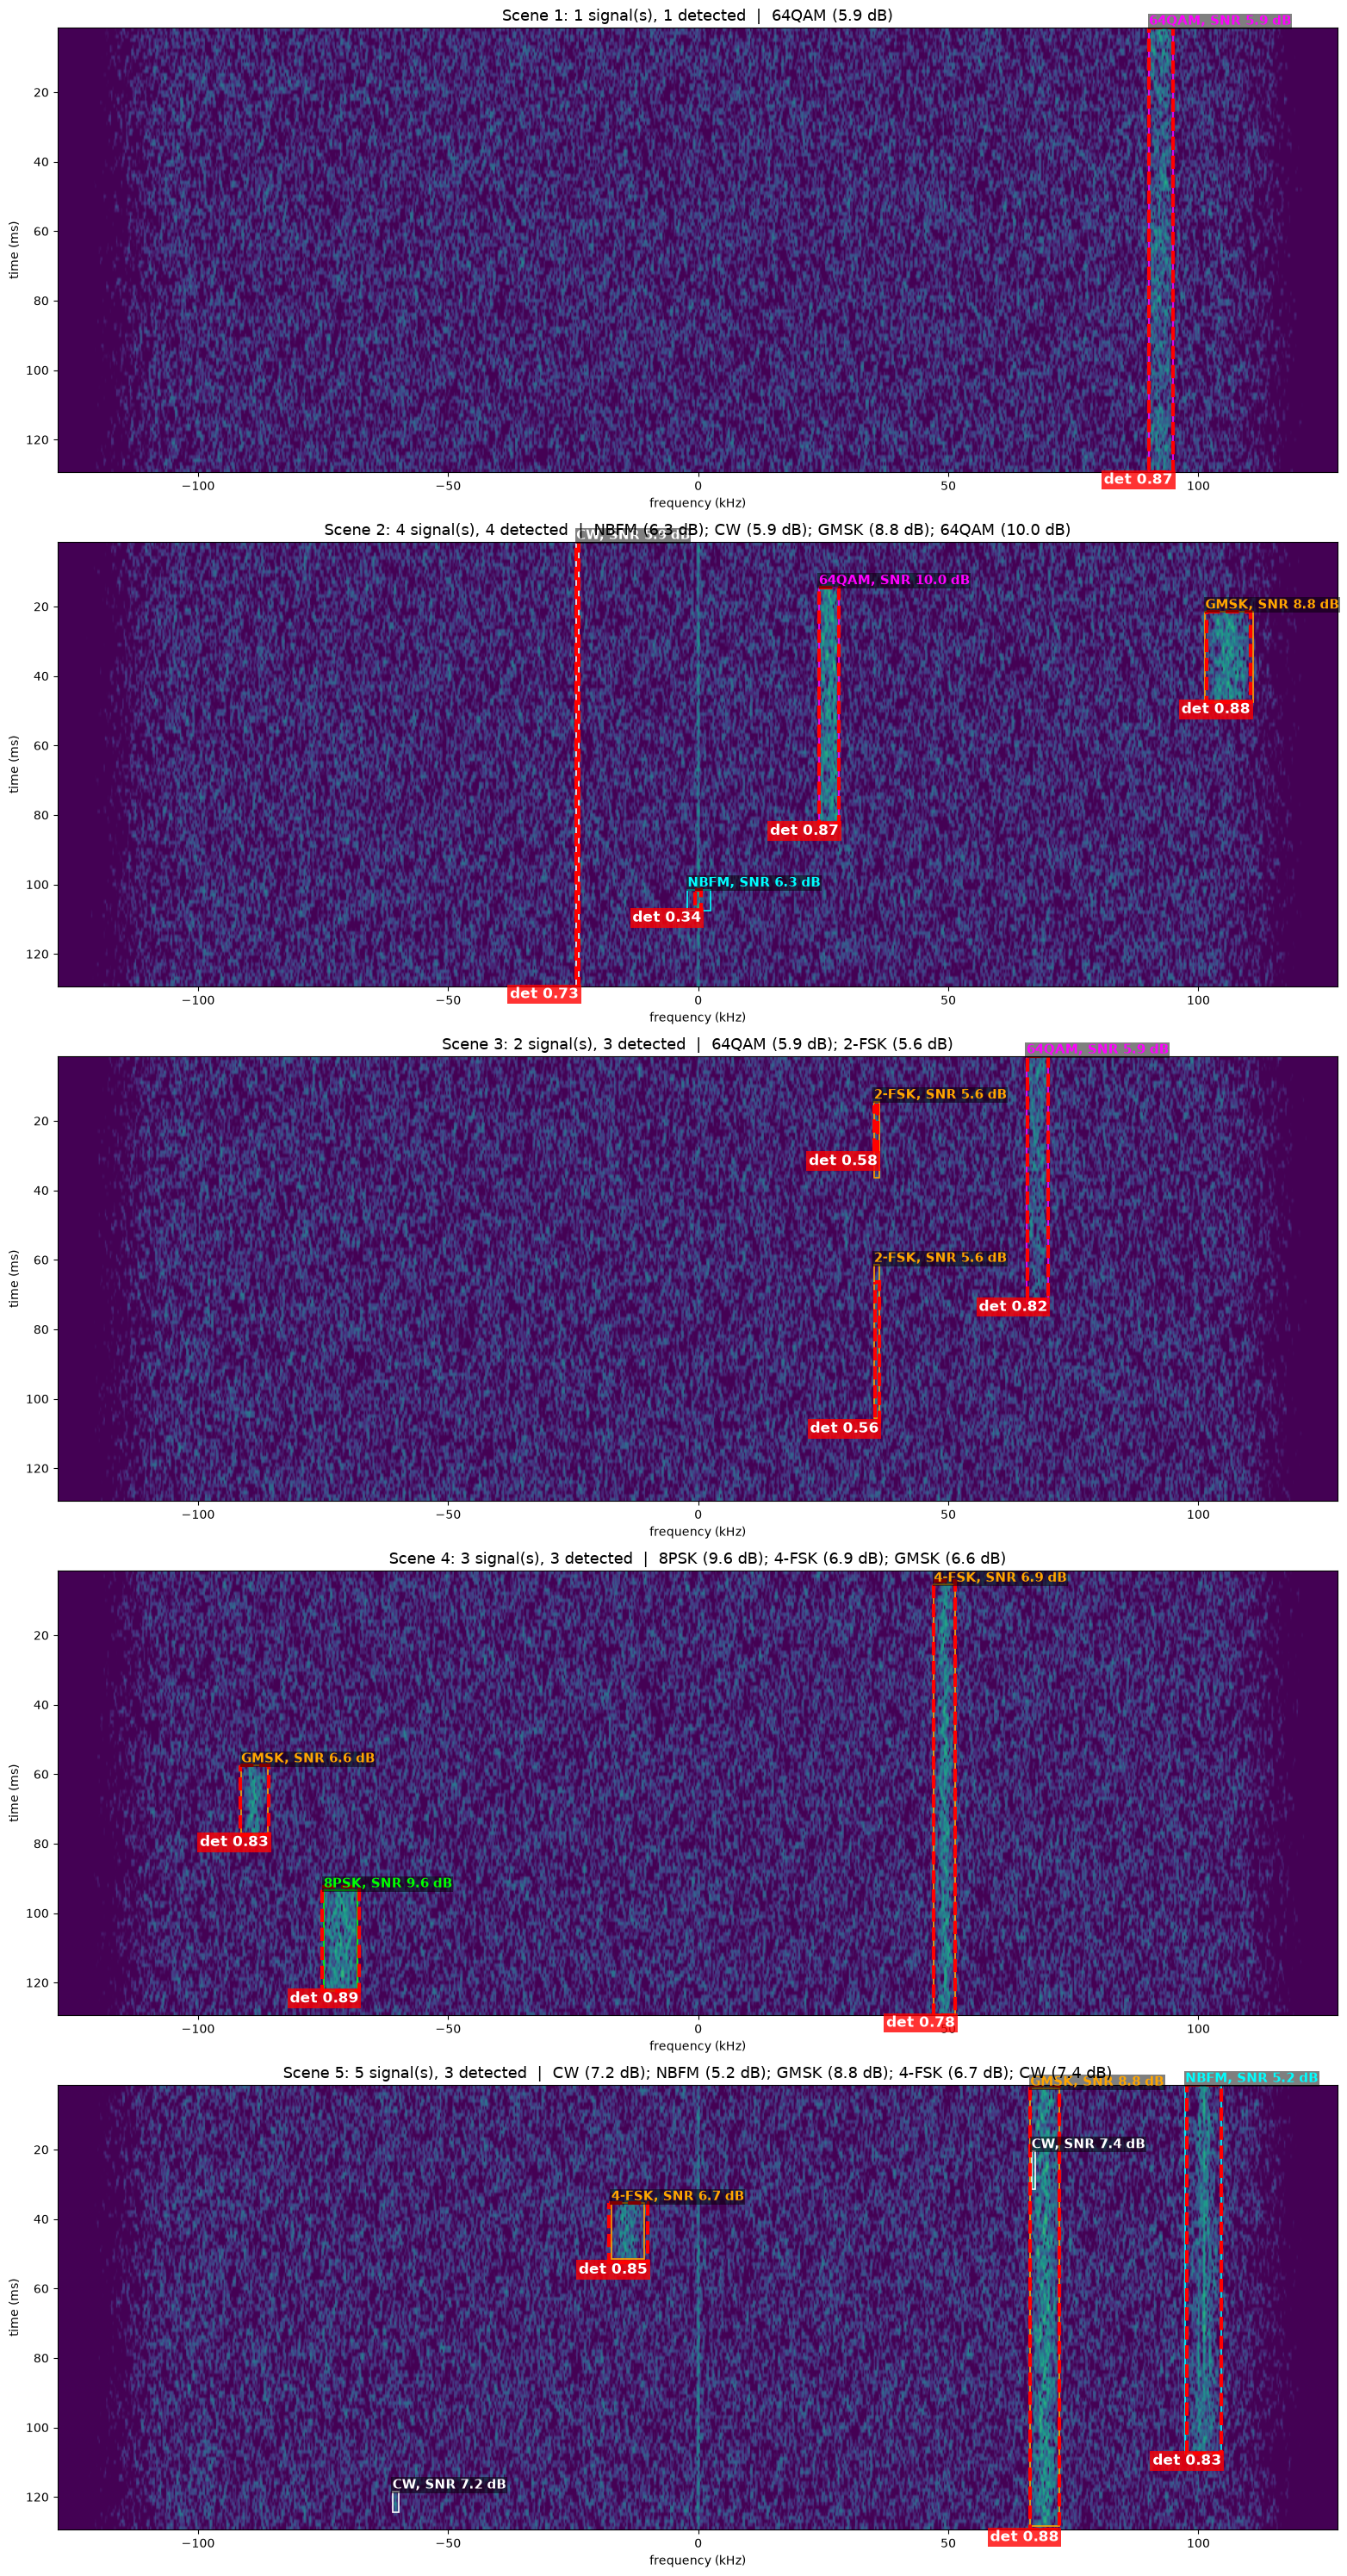

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def box_to_axes(x0, y0, x1, y1):
    f0 = (x0 - CFG.n_fft / 2 - 0.5) * DF / 1e3
    f1 = (x1 - CFG.n_fft / 2 + 0.5) * DF / 1e3
    t0 = (y0 * CFG.hop + CFG.n_fft / 2 - CFG.hop / 2) / FS * 1e3
    t1 = (y1 * CFG.hop + CFG.n_fft / 2 + CFG.hop / 2) / FS * 1e3
    return f0, f1, t0, t1

FAM = {1: "white", 2: "yellow", 3: "cyan", 4: "lime", 5: "magenta", 6: "orange", 7: "red"}
fig, axes = plt.subplots(len(scenes), 1, figsize=(16, 6 * len(scenes)))
for k, (ax, sc, pr) in enumerate(zip(axes, scenes, preds), 1):
    plot_scene(sc, ax=ax)
    [t.remove() for t in list(ax.texts)]                            # replace the default small labels by modulation + SNR
    for r in sc["signals"]:
        f0, f1, t0, t1 = box_to_axes(r["box_x0"], r["box_y0"], r["box_x1"], r["box_y1"])
        ax.text(f0, t0, f'{r["class_name"]}, SNR {r["snr_db"]:.1f} dB', color=FAM[r["family_id"]], fontsize=11, fontweight="bold", va="bottom",
                bbox=dict(fc="black", alpha=0.5, pad=1, lw=0))
    for d in pr:
        f0, f1, t0, t1 = box_to_axes(*d["box"])
        ax.add_patch(Rectangle((f0, t0), f1 - f0, t1 - t0, fill=False, ec="red", ls="--", lw=3))
        ax.text(f1, t1, f'det {d["score"]:.2f}', color="white", fontsize=12, fontweight="bold", ha="right", va="top",
                bbox=dict(fc="red", alpha=0.8, pad=2, lw=0))
    sigs = {(r["sig_idx"]): r for r in sc["signals"]}.values()
    ax.set_title(f"Scene {k}: {len(sigs)} signal(s), {len(pr)} detected  |  " + "; ".join(f'{r["class_name"]} ({r["snr_db"]:.1f} dB)' for r in sigs), fontsize=13)
plt.tight_layout()
plt.show()

## 4. Per-scene summary

In [ ]:
import pandas as pd
rows = []
for k, (sc, pr) in enumerate(zip(scenes, preds)):
    gt = [tuple(r[c] for c in ("box_x0", "box_y0", "box_x1", "box_y1")) for r in sc["signals"]]
    pb = [d["box"] for d in pr]
    ious = box_iou_matrix(gt, pb)
    for j, r in enumerate(sc["signals"]):   # one row per burst box
        best = float(ious[j].max()) if ious.shape[1] else 0.0
        rows.append(dict(scene=k + 1, modulation=r["class_name"], snr_db=round(r["snr_db"], 1), burst=r["burst_type"],
                         center_kHz=round(r["center_hz"] / 1e3, 1), best_iou=round(best, 2), detected=best >= 0.5))
df = pd.DataFrame(rows)
display(df)
print(f"recall @ IoU 0.5: {df.detected.mean():.0%} | false positives: {sum(len(p) for p in preds) - int(df.detected.sum())}")

## 5. Overlapping signals and 1 kHz separation

Two controlled situations, each **never both at once** (a signal pair that overlaps in time *and* in frequency is a collision nobody can separate):

| Case | Signals overlap in | Signals do **not** overlap in |
|---|---|---|
| **Time overlap** | time (they are on air together) | frequency (their occupied bands are apart) |
| **Frequency overlap** | frequency (centres only about 1 kHz apart, bands overlap) | time (they transmit one after the other) |

The generator is told the exact centre frequency and burst interval of each signal. Every scene is then **checked from the generated ground-truth boxes** (99% power band and burst times) and regenerated until it satisfies its case. Each case reports recall and precision over many scenes, and the plots show examples.

Section 5.3 is the **1 kHz separation test**: two signals exactly 1 kHz apart, on air together. It is a success only if the detector returns **two** boxes, each with its centre within +-250 Hz (one bin) of a true signal.

In [ ]:
from scipy.optimize import linear_sum_assignment
from spectrum_common import N_FFT, box_center_hz, box_times_ms, match_detections

MS = FS / 1e3                                                  # samples per ms
SNR_CASES = SNR_RANGE                                          # SNR of every signal in section 5 (dB)
WIDE_CLASSES = ["QPSK", "8PSK", "16QAM", "GMSK", "NBFM", "AM", "2-FSK"]   # carry real bandwidth, so overlapping bands are easy to build
N_EVAL = 30                                                    # scenes per case for the statistics
rng5 = np.random.default_rng(None if SEED is None else SEED + 1)


def make_demo_scene(items, seed, name):
    """items: dicts with cls, snr_db, fc_hz, t0_ms, t1_ms (and optional rs = baud range)."""
    spec = make_specs("val", 0, 1)[0]
    spec.update(seed=int(seed), scene_id=name, session=session_for_group(SET_IDS["val"], 0, "train"))
    spec["force"] = [dict(cls=i["cls"], snr_db=i["snr_db"], fc_hz=i["fc_hz"], rs_override=i.get("rs"),
                          intervals=[(int(round(i["t0_ms"] * MS)), int(round(i["t1_ms"] * MS)))]) for i in items]
    sc = make_scene(spec)
    sc["db"] = dequantize_db(sc["spec"])
    return sc


def pair_overlaps(sig):
    """For every pair of signals: do their occupied bands / burst times overlap? Returns two lists of booleans."""
    fo, to = [], []
    for a in range(len(sig)):
        for b in range(a + 1, len(sig)):
            ra, rb = sig[a], sig[b]
            fo.append(min(ra["f_hi_hz"], rb["f_hi_hz"]) - max(ra["f_lo_hz"], rb["f_lo_hz"]) > 0)
            to.append(min(ra["t_end_s"], rb["t_end_s"]) - max(ra["t_start_s"], rb["t_start_s"]) > 0)
    return fo, to


def case_ok(kind, sig):
    fo, to = pair_overlaps(sig)
    return (all(to) and not any(fo)) if kind == "time" else (all(fo) and not any(to))


def sample_items(kind, rng):
    snr = lambda: float(rng.uniform(*SNR_CASES))
    if kind == "time":                                         # on air together, bands far apart
        n = int(rng.integers(2, 5))
        slots = rng.choice([-90, -60, -30, 30, 60, 90], size=n, replace=False)
        items = []
        for s in slots:
            t0 = float(rng.uniform(2, 50))
            items.append(dict(cls=str(rng.choice(CLASSES)), snr_db=snr(), fc_hz=float(s * 1e3 + rng.uniform(-5e3, 5e3)),
                              t0_ms=t0, t1_ms=min(t0 + float(rng.uniform(40, 75)), 128.0)))
        return items
    n = int(rng.integers(2, 4))                                # frequency overlap: same band, one after the other
    edges = np.linspace(2, 128, n + 1)
    c0 = float(rng.uniform(-70e3, 70e3))
    return [dict(cls=str(rng.choice(WIDE_CLASSES)), snr_db=snr(), fc_hz=c0 + float(rng.uniform(-1e3, 1e3)),
                 t0_ms=float(edges[k] + rng.uniform(1, 4)), t1_ms=float(edges[k + 1] - rng.uniform(1, 4))) for k in range(n)]


def gen_case(kind, rng, name, tries=100):
    for _ in range(tries):
        sc = make_demo_scene(sample_items(kind, rng), rng.integers(0, 2**62), name)
        if case_ok(kind, sc["signals"]):
            sc["kind"] = kind
            return sc
    raise RuntimeError(f"no valid {kind} scene after {tries} tries")


def score_scene(sc, pr, thr=0.5):
    gt = [tuple(r[c] for c in ("box_x0", "box_y0", "box_x1", "box_y1")) for r in sc["signals"]]
    pb = [d["box"] for d in pr]
    m = match_detections(pb, [d["score"] for d in pr], gt, thr)
    ious = box_iou_matrix(pb, gt)
    return dict(n_gt=len(gt), n_pred=len(pb), tp=int((m >= 0).sum()),
                iou_sum=float(sum(ious[p, g] for p, g in enumerate(m) if g >= 0)))


def draw(ax, sc, pr, title, xlim=None, fs=11):
    plot_scene(sc, ax=ax, title=title, xlim=xlim)
    [t.remove() for t in list(ax.texts)]
    inside = lambda f0, f1: xlim is None or (xlim[0] <= (f0 + f1) / 2 <= xlim[1])    # no labels outside the zoomed range
    for r in sc["signals"]:
        f0, f1, t0, t1 = box_to_axes(r["box_x0"], r["box_y0"], r["box_x1"], r["box_y1"])
        if inside(f0, f1):
            ax.text(f0, t0, f'{r["class_name"]}, SNR {r["snr_db"]:.1f} dB', color=FAM[r["family_id"]], fontsize=fs, fontweight="bold",
                    va="bottom", bbox=dict(fc="black", alpha=0.5, pad=1, lw=0))
    for d in pr:
        f0, f1, t0, t1 = box_to_axes(*d["box"])
        if not inside(f0, f1):
            continue
        ax.add_patch(Rectangle((f0, t0), f1 - f0, t1 - t0, fill=False, ec="red", ls="--", lw=3))
        ax.text(f1, t1, f'det {d["score"]:.2f}', color="white", fontsize=fs, fontweight="bold", ha="right", va="top",
                bbox=dict(fc="red", alpha=0.8, pad=2, lw=0))
    ax.set_title(title, fontsize=13)

### 5.1 Time overlap (signals on air together, bands apart) and 5.2 frequency overlap (same band, one after the other)

In [ ]:
CASES = {}
for kind in ("time", "freq"):
    scs = [gen_case(kind, rng5, f"{kind}_{k}") for k in range(N_EVAL)]
    prs = det.detect_batch([s["db"] for s in scs])
    CASES[kind] = (scs, prs)

rows = []
for kind, label in (("time", "time overlap (frequency apart)"), ("freq", "frequency overlap (time apart)")):
    scs, prs = CASES[kind]
    sc_ = pd.DataFrame([score_scene(s, p) for s, p in zip(scs, prs)])
    tp, ng, npd = sc_.tp.sum(), sc_.n_gt.sum(), sc_.n_pred.sum()
    rows.append(dict(case=label, scenes=len(scs), signals=int(ng), recall=tp / ng, precision=tp / max(npd, 1),
                     mean_iou=sc_.iou_sum.sum() / max(tp, 1), scenes_all_found=float((sc_.tp == sc_.n_gt).mean()),
                     false_alarms_per_scene=float((sc_.n_pred - sc_.tp).mean())))
display(pd.DataFrame(rows).set_index("case").round(3))

In [ ]:
for kind, title in (("time", "TIME overlap: signals on air together, bands do not overlap"),
                    ("freq", "FREQUENCY overlap: bands overlap, signals never on air together")):
    scs, prs = CASES[kind]
    fig, axes = plt.subplots(3, 1, figsize=(16, 18))
    fig.suptitle(title, fontsize=15, y=0.995)
    for ax, sc, pr in zip(axes, scs[:3], prs[:3]):
        sg = sc["signals"]
        draw(ax, sc, pr, f'{len(sg)} signals, {len(pr)} detected  |  ' + "; ".join(f'{r["class_name"]} ({r["snr_db"]:.1f} dB)' for r in sg))
    plt.tight_layout()
    plt.show()

### 5.3 The 1 kHz separation test

30 scenes, two signals **exactly 1 kHz apart** (10 per bandwidth tier: T1 narrowest, T2 narrow, T3 normal symbol rates), both on air for the whole scene. Success = two detections, each centre within +-250 Hz of a different true signal and overlapping its burst in time. Failure types: **merged** (one box spans both signals), **missed** (a signal has no detection), **other**.

In [ ]:
SEP_HZ, TOL_HZ = 1000.0, 250.0
TIERS = {"T1": (100, 300), "T2": (300, 700), "T3": None}
NARROW_POOL = ["CW", "BPSK", "QPSK", "2-FSK", "GMSK"]


def sep_scene(tier, rng, name):
    pool = CLASSES if tier == "T3" else NARROW_POOL
    mid = float(rng.uniform(-80e3, 80e3))
    return make_demo_scene([dict(cls=str(rng.choice(pool)), snr_db=float(rng.uniform(*SNR_CASES)), fc_hz=mid + o * SEP_HZ / 2,
                                 t0_ms=0.0, t1_ms=NS / MS, rs=TIERS[tier]) for o in (-1, 1)], rng.integers(0, 2**62), name)


def sep_outcome(sc, pr):
    g = sc["signals"]
    gc = np.array([r["center_hz"] for r in g])
    g0, g1 = np.array([r["t_start_s"] for r in g]) * 1e3, np.array([r["t_end_s"] for r in g]) * 1e3
    dc = np.array([box_center_hz(d["box"]) for d in pr])
    dt = np.array([box_times_ms(d["box"]) for d in pr]).reshape(-1, 2)
    ok = np.zeros((len(g), len(pr)), bool)
    for i in range(len(g)):
        for j in range(len(pr)):
            ov = min(g1[i], dt[j, 1]) - max(g0[i], dt[j, 0])
            ok[i, j] = abs(gc[i] - dc[j]) <= TOL_HZ and ov >= 0.3 * (g1[i] - g0[i])
    if ok.any():
        r_, c_ = linear_sum_assignment(-ok.astype(float))
        if ok[r_, c_].sum() == len(g):
            return "success"
    lo = np.array([(d["box"][0] - N_FFT / 2) * DF for d in pr])                 # detection band edges (Hz)
    hi = np.array([(d["box"][2] + 1 - N_FFT / 2) * DF for d in pr])
    if len(pr) and ((lo <= gc.min() + TOL_HZ) & (hi >= gc.max() - TOL_HZ)).any():
        return "merged"                                                         # one box spans both signals
    return "missed" if (not len(pr) or ok.any(axis=1).sum() < len(g)) else "other"


sep_scs = [sep_scene(t, rng5, f"sep_{t}_{k}") for t in TIERS for k in range(N_EVAL // 3)]
for s, t in zip(sep_scs, [t for t in TIERS for _ in range(N_EVAL // 3)]):
    s["tier"] = t
sep_prs = det.detect_batch([s["db"] for s in sep_scs])
res = pd.DataFrame(dict(tier=[s["tier"] for s in sep_scs], outcome=[sep_outcome(s, p) for s, p in zip(sep_scs, sep_prs)],
                        spacing_hz=[abs(s["signals"][0]["center_hz"] - s["signals"][1]["center_hz"]) for s in sep_scs]))
print(f"true spacing in every scene: {res.spacing_hz.min():.0f} to {res.spacing_hz.max():.0f} Hz")
tab = pd.crosstab(res.tier, res.outcome).reindex(columns=["success", "merged", "missed", "other"], fill_value=0)
tab.loc["all"] = tab.sum()
tab["success_rate"] = (tab.success / tab[["success", "merged", "missed", "other"]].sum(axis=1)).round(3)
display(tab)

In [ ]:
pick = [next(i for i, s in enumerate(sep_scs) if s["tier"] == t) for t in TIERS]
fig, axes = plt.subplots(len(pick), 1, figsize=(16, 6 * len(pick)))
for ax, i in zip(axes, pick):
    sc, pr = sep_scs[i], sep_prs[i]
    mid = np.mean([r["center_hz"] for r in sc["signals"]]) / 1e3
    sg = sc["signals"]
    draw(ax, sc, pr, f'1 kHz pair, tier {sc["tier"]}: ' + " + ".join(f'{r["class_name"]} ({r["snr_db"]:.1f} dB)' for r in sg) +
         f"   ->  {sep_outcome(sc, pr)}  ({len(pr)} detections)", xlim=(mid - 6, mid + 6), fs=10)
plt.tight_layout()
plt.show()